# CALCE raw battery data → validated cycle features → quantitative feature selection

**Purpose:** Research-grade, auditable preprocessing of CALCE CX2/CS2 *raw measurement spreadsheets* into cycle-level SOH features. This pipeline does **not** assume that unknown timestamp gaps are rest, does not fabricate discharge labels, and does not treat a row of raw samples as a cycle.

**Outputs:** extraction/QC audit, per-cycle features and provenance, Pearson/Spearman/Kendall correlations, mutual information, bootstrap uncertainty, feature redundancy, cell-disjoint ranking and held-out validation, plots and paper-ready CSVs.

**Instructions:** Set `RAW_ROOT` below to the original folder with `Channel_*.xlsx` / equivalent; use the `inspect` cell first. If your Excel schema differs, edit `COLUMN_ALIASES`. Data-free notebook: real numbers appear **only after processing your actual files**. Dependencies: `pip install pandas numpy scipy scikit-learn matplotlib openpyxl tqdm`.

**Scope:** charge-derived CC/CV, ICA/DVA features; SOH target from **observed discharge capacity** only. Do not use future-cycle records for feature extraction, and use battery-disjoint validation for claims of cross-cell generalization.

In [13]:
from pathlib import Path
import re, json, math, warnings, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import savgol_filter, find_peaks, peak_widths
from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.feature_selection import mutual_info_regression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold
from tqdm.auto import tqdm
from IPython.display import display

RAW_ROOT = Path(r'C:\Projects\Battery_Soh\data')   # CHANGE THIS
OUT_DIR = Path('calce_raw_feature_research')
OUT_DIR.mkdir(exist_ok=True, parents=True)
CELL_PREFIXES = ('CX2', 'CS2')
NOMINAL_AH_BY_SERIES = {'CX2': 1.35, 'CS2': 1.10}  # verify against raw metadata and cell datasheet
# Interpret sign using charge metadata when available; otherwise charge usually + and discharge -.
CURRENT_SIGN = 'auto'   # 'auto', 'charge_positive', 'charge_negative'
CHARGE_CURRENT_MIN_A = 0.025
DISCHARGE_CURRENT_MIN_A = 0.025
CV_THRESHOLD_V = 4.18
IC_WINDOW_V = (3.80, 4.15)
MAX_SAMPLE_GAP_SECONDS = 600  # never integrate across gaps above this
MIN_CHARGE_POINTS = 45
MIN_DISCHARGE_POINTS = 45
MIN_CHARGE_SPAN_V = 0.15
MIN_VALID_DISCHARGE_AH = 0.15
LABEL_MAX_RATIO = 1.35
CAPACITY_SOURCE = 'integrated_discharge'  # require actually observed negative-current discharge
MAX_FILES = None   # e.g. 3 for a smoke test
RANDOM_STATE = 42
print('Raw path:', RAW_ROOT, '| Exists:', RAW_ROOT.exists())
print('Output:', OUT_DIR.resolve())

Raw path: C:\Projects\Battery_Soh\data | Exists: True
Output: C:\Projects\Battery_Soh\calce_raw_feature_research


## 1. Inventory, schema inspection and provenance

Only measurement/channel sheets are used for extraction; statistics/summary sheets are explicitly excluded to prevent mixing aggregate and sample-level rows. The inventory reports every workbook/sheet, including errors. A sheet must contain time, current, and voltage columns.

In [14]:
COLUMN_ALIASES = {
 'time_s': ['test_time_s','test_time','total_time_s','total_time','time_s','time','time_sec', 'testtime'],
 'datetime': ['date_time','datetime','date','timestamp','absolute_time'],
 'current_a': ['current_a','current','i_a','amps','currentamp'],
 'voltage_v': ['voltage_v','voltage','ewe_v','v_v','potential_v'],
 'capacity_ah': ['capacity_ah','discharge_capacity_ah','ah','amp_hr','amphr'],
 'charge_capacity_ah': ['charge_capacity_ah','charge_capacity'],
 'discharge_capacity_ah': ['discharge_capacity_ah','discharge_capacity'],
 'step': ['step_index','step','step_id','step_number','step_num'],
 'cycle': ['cycle_index','cycle','cycle_number','cycle_id'],
 'mode': ['step_type','state','status','mode','control_mode','step_name'],
 'temperature_c': ['temperature_c','temperature','temp_c','temp'],
}
def norm_col(c):
    s=str(c).lower().strip()
    s=re.sub(r'\([^)]*\)', '', s) if False else s
    s=s.replace('(','_').replace(')','_').replace('[','_').replace(']','_').replace('/','_')
    return re.sub(r'[^a-z0-9]+','_',s).strip('_')
def match_columns(df):
    normalized={norm_col(c):c for c in df.columns}
    result={}
    for canonical, aliases in COLUMN_ALIASES.items():
        for a in [canonical]+aliases:
            if norm_col(a) in normalized:
                result[canonical]=normalized[norm_col(a)]; break
    return result

def parse_cell_id(path):
    # Entire path as independent components: avoids earlier CS2_33 -> CS2_2 error.
    matches=re.findall(r'(?i)(?:^|[^a-z0-9])((?:CX2|CS2)[_-]?(?:\d{1,3}))(?!\d)', str(path))
    if not matches: return None
    v=matches[-1].upper().replace('-','_')
    return re.sub(r'^(CX2|CS2)_?(\d+)$', r'\1_\2',v)
assert parse_cell_id(r'C:\dataset\CS2_33\Channel_1-007.xlsx')=='CS2_33'
assert parse_cell_id(r'C:\dataset\CX2_16\Channel_1-009.xlsx')=='CX2_16'

def discover_raw_files(root):
    files=sorted(x for ext in ('*.xlsx','*.xlsm','*.csv') for x in root.rglob(ext)
                 if not x.name.startswith('~$') and 'feature_' not in x.name.lower())
    return files[:MAX_FILES] if MAX_FILES else files
files=discover_raw_files(RAW_ROOT) if RAW_ROOT.exists() else []
inventory=pd.DataFrame([{'file':str(p),'cell_id':parse_cell_id(p),'size_mb':round(p.stat().st_size/1e6,2)} for p in files])
print('Files found:', len(files), '| identified cells:', sorted(inventory.cell_id.dropna().unique()) if len(inventory) else [])
display(inventory.head(20))
inventory.to_csv(OUT_DIR/'file_inventory.csv',index=False)

Files found: 526 | identified cells: ['CX2_16', 'CX2_3', 'CX2_32', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_36', 'CX2_37', 'CX2_38', 'CX2_4', 'CX2_8']


,file,cell_id,size_mb
0,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,CX2_16,3.35
1,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,CX2_16,0.47
2,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,CX2_16,2.59
3,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,CX2_16,3.80
4,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,CX2_16,3.19
5,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,CX2_16,2.74
6,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,CX2_16,0.05
7,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,CX2_16,4.26
8,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,CX2_16,3.68
9,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,CX2_16,0.09


In [15]:
def sheets_in_file(path):
    if path.suffix.lower()=='.csv': return ['__csv__']
    return pd.ExcelFile(path, engine='openpyxl').sheet_names

def read_sheet(path,sheet,nrows=None):
    if sheet=='__csv__': return pd.read_csv(path,nrows=nrows,low_memory=False)
    return pd.read_excel(path,sheet_name=sheet,nrows=nrows,engine='openpyxl')

def is_raw_sheet(name):
    s=name.lower()
    return not any(word in s for word in ['statistics','summary','statistic','feature','metadata','info','chart'])

schema_rows=[]
for p in tqdm(files,desc='Inspecting workbook schemas'):
    try:
        for sh in sheets_in_file(p):
            entry={'file':str(p),'sheet':sh,'cell_id':parse_cell_id(p)}
            if not is_raw_sheet(sh): entry.update(status='excluded_summary_sheet'); schema_rows.append(entry); continue
            sample=read_sheet(p,sh,nrows=8)
            mapping=match_columns(sample)
            entry.update(status='candidate' if {'current_a','voltage_v'}<=set(mapping) and ('time_s' in mapping or 'datetime' in mapping) else 'missing_columns',
                         detected_columns=json.dumps(mapping),n_columns=len(sample.columns),columns=json.dumps(list(map(str,sample.columns))))
            schema_rows.append(entry)
    except Exception as e:
        schema_rows.append({'file':str(p),'sheet':'','cell_id':parse_cell_id(p),'status':'read_error','error':str(e)[:500]})
schema=pd.DataFrame(schema_rows)
schema.to_csv(OUT_DIR/'sheet_schema_inventory.csv',index=False)
print(schema.status.value_counts(dropna=False).to_string() if len(schema) else 'NO FILES. Set RAW_ROOT and rerun.')
display(schema.head(12))

Inspecting workbook schemas:   0%|          | 0/526 [00:00<?, ?it/s]

status
excluded_summary_sheet    679
candidate                 457
read_error                107
missing_columns             2


,file,sheet,cell_id,status,detected_columns,n_columns,columns,error
0,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,Info,CX2_16,excluded_summary_sheet,NaN,NaN,NaN,NaN
1,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,Channel_1-006,CX2_16,candidate,"{""time_s"": ""Test_Time(s)"", ""datetime"": ""Date_T...",17.0,"[""Data_Point"", ""Test_Time(s)"", ""Date_Time"", ""S...",NaN
2,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,Statistics_1-006,CX2_16,excluded_summary_sheet,NaN,NaN,NaN,NaN
3,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,Info,CX2_16,excluded_summary_sheet,NaN,NaN,NaN,NaN
4,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,Channel_1-006,CX2_16,candidate,"{""time_s"": ""Test_Time(s)"", ""datetime"": ""Date_T...",17.0,"[""Data_Point"", ""Test_Time(s)"", ""Date_Time"", ""S...",NaN
5,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,Statistics_1-006,CX2_16,excluded_summary_sheet,NaN,NaN,NaN,NaN
6,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,Info,CX2_16,excluded_summary_sheet,NaN,NaN,NaN,NaN
7,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,Channel_1-006,CX2_16,candidate,"{""time_s"": ""Test_Time(s)"", ""datetime"": ""Date_T...",17.0,"[""Data_Point"", ""Test_Time(s)"", ""Date_Time"", ""S...",NaN
8,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,Statistics_1-006,CX2_16,excluded_summary_sheet,NaN,NaN,NaN,NaN
9,C:\Projects\Battery_Soh\data\CX2_16\CX2_16\CX2...,Info,CX2_16,excluded_summary_sheet,NaN,NaN,NaN,NaN


## 2. Convert channel tables to canonical measurements

Time is converted to seconds; duplicate timestamps are removed within a sheet. Integration occurs only between consecutive accepted observations inside a contiguous charge or discharge segment. A long inter-session gap is **not** counted as charge, discharge, or rest. **No assumption about observed rest** is made here.

In [16]:
def make_canonical(raw, path, sheet):
    m=match_columns(raw)
    need={'current_a','voltage_v'}
    if not need<=set(m) or ('time_s' not in m and 'datetime' not in m):
        raise ValueError('missing time/current/voltage')
    out=pd.DataFrame(index=raw.index)
    for field in ('current_a','voltage_v','capacity_ah','charge_capacity_ah','discharge_capacity_ah','step','cycle','mode','temperature_c'):
        if field in m: out[field]=raw[m[field]]
    for field in ('current_a','voltage_v','capacity_ah','charge_capacity_ah','discharge_capacity_ah','step','cycle','temperature_c'):
        if field in out: out[field]=pd.to_numeric(out[field],errors='coerce')
    if 'time_s' in m:
        s=raw[m['time_s']]
        if pd.api.types.is_numeric_dtype(s): out['t_raw']=pd.to_numeric(s,errors='coerce')
        else:
            # hh:mm:ss clock-duration strings; numeric strings parsed as numeric seconds
            numeric=pd.to_numeric(s,errors='coerce')
            out['t_raw']=numeric if numeric.notna().mean()>.8 else pd.to_timedelta(s.astype(str),errors='coerce').dt.total_seconds()
    else:
        out['t_raw']=(pd.to_datetime(raw[m['datetime']],errors='coerce')-pd.Timestamp('1970-01-01')).dt.total_seconds()
    out['file']=str(path); out['sheet']=sheet
    out=out.dropna(subset=['t_raw','current_a','voltage_v']).copy()
    out=out[(out.voltage_v.between(1.5,5.1)) & (out.current_a.abs()<20)]
    out=out.sort_values('t_raw',kind='stable').drop_duplicates('t_raw',keep='last').reset_index(drop=True)
    if len(out): out['t_s']=out.t_raw-out.t_raw.iloc[0]
    return out

def contiguous_segments(df):
    # Separate by polarity and large gaps; mode hints can override nonzero-current polarity inference.
    if len(df)<2:return []
    cur=df.current_a.to_numpy(float); t=df.t_s.to_numpy(float)
    status=np.where(np.abs(cur)<min(CHARGE_CURRENT_MIN_A,DISCHARGE_CURRENT_MIN_A),'idle',np.where(cur>0,'positive','negative'))
    if 'mode' in df:
        txt=df['mode'].fillna('').astype(str).str.lower().to_numpy()
        status=np.where(np.char.find(txt.astype(str),'discharg')>=0,'discharge',status)
        status=np.where(np.char.find(txt.astype(str),'charg')>=0,'charge',status)
        status=np.where(np.char.find(txt.astype(str),'rest')>=0,'idle',status)
    gaps=np.r_[True,(np.diff(t)>MAX_SAMPLE_GAP_SECONDS)|(np.diff(t)<=0)]
    transitions=np.r_[True,status[1:]!=status[:-1]]
    if 'cycle' in df:
        cycle=df.cycle.to_numpy()
        transitions[1:] |= (cycle[1:]!=cycle[:-1]) & np.isfinite(cycle[1:]) & np.isfinite(cycle[:-1])
    ids=np.cumsum(gaps|transitions)
    return [(int(k),g.reset_index(drop=True),status[g.index[0]]) for k,g in df.groupby(ids,sort=False)]

def detect_polarity(df):
    if CURRENT_SIGN=='charge_positive':return 1,'configured'
    if CURRENT_SIGN=='charge_negative':return -1,'configured'
    # Inspect voltage trend during signed-current segments; rising voltage implies charging.
    scores={}
    for sign in (1,-1):
        g=df[(np.sign(df.current_a)==sign)&(df.current_a.abs()>=CHARGE_CURRENT_MIN_A)]
        dv=g.voltage_v.diff(); dt=g.t_s.diff()
        delta=dv[(dt>0)&(dt<MAX_SAMPLE_GAP_SECONDS)]
        scores[sign]=float(delta.median()) if len(delta.dropna()) else np.nan
    if np.isfinite(scores[1]) and np.isfinite(scores[-1]):
        if abs(scores[1]-scores[-1])<1e-5: return None,'ambiguous_voltage_slope'
        return (1 if scores[1]>scores[-1] else -1),'voltage_slope_heuristic'
    return None,'insufficient_polarity_evidence'

def trapezoid_ah(df):
    if len(df)<2:return np.nan
    delta_t=np.diff(df.t_s.to_numpy(float))
    valid=(delta_t>0)&(delta_t<=MAX_SAMPLE_GAP_SECONDS)
    amps=np.abs(df.current_a.to_numpy(float))
    return float(np.sum(.5*(amps[1:]+amps[:-1])*delta_t*valid)/3600)

# For noisy split charge steps, this is a provisional reconstruction. Its cycle alignment is audited below.

## 3. Feature engineering from charge segments

Definition of the five previously selected F2 features: CC duration (s) below 4.18 V; CV duration (s) at/above 4.18 V and declining current; maximum smoothed dV/dQ (V/Ah); IC peak voltage (V) and half-prominence width (V). The precise filters below are declared and saved; these values are research choices, not claims about the original unpublished feature extractor.

ICA/DVA uses monotonic charging-voltage reconstruction, voltage binning, interpolation, and Savitzky–Golay smoothing. Invalid or insufficient curves yield `NaN` with a QC reason rather than made-up peaks.

In [17]:
def smooth_curve_features(charge):
    result={'dva_peak':np.nan,'ic_peak_voltage':np.nan,'ic_peak_width':np.nan,'curve_qc':'not_enough_points'}
    if len(charge)<MIN_CHARGE_POINTS:return result
    v=charge.voltage_v.to_numpy(float); current=np.abs(charge.current_a.to_numpy(float)); t=charge.t_s.to_numpy(float)
    dt=np.diff(t)
    if np.any(dt<=0) or (v.max()-v.min())<MIN_CHARGE_SPAN_V:
        result['curve_qc']='time_or_voltage_span';return result
    inc=np.r_[0, .5*(current[1:]+current[:-1])*dt/3600]
    q=np.cumsum(inc)
    if q[-1]<.05:result['curve_qc']='insufficient_charge_ah';return result
    # Restrict to monotonic upper envelope in Q; collapse repeated V by voltage bins.
    tbl=pd.DataFrame({'v':v,'q':q}).sort_values('v')
    bins=np.round(tbl.v.to_numpy()/0.005)*0.005
    unique=pd.DataFrame({'v':bins,'q':tbl.q}).groupby('v',as_index=False).q.median().sort_values('v')
    if len(unique)<18:result['curve_qc']='few_voltage_bins';return result
    vg=np.arange(max(float(unique.v.min()),3.0),min(float(unique.v.max()),4.3)+1e-8,.005)
    if len(vg)<21:result['curve_qc']='few_interpolated_points';return result
    qg=np.interp(vg,unique.v,unique.q)
    qg=np.maximum.accumulate(qg)
    win=min(15,(len(vg)//2)*2-1)
    if win<7:result['curve_qc']='smoothing_window';return result
    qsm=savgol_filter(qg,win,2)
    ic=np.gradient(qsm,vg)
    ic=savgol_filter(ic,win,2)
    good=(vg>=IC_WINDOW_V[0])&(vg<=IC_WINDOW_V[1])
    interior=np.where(good)[0]
    if len(interior)<9:result['curve_qc']='no_ic_voltage_coverage';return result
    peaks,props=find_peaks(ic,prominence=max(float(np.nanmax(ic[good]))*.06,0.005))
    peaks=[p for p in peaks if good[p]]
    if not peaks:result['curve_qc']='no_prominent_ic_peak';return result
    peak=max(peaks,key=lambda p:ic[p]); half=peak_widths(ic,[peak],rel_height=.5)
    width_v=float(half[0][0]*.005)
    # dV/dQ is only meaningful where dQ/dV sufficiently positive.
    valid=good&(ic>0.02)
    dva=np.divide(1.0,ic,out=np.full_like(ic,np.nan),where=valid)
    result.update(ic_peak_voltage=float(vg[peak]),ic_peak_width=width_v,
                  dva_peak=float(np.nanmax(dva)) if np.any(np.isfinite(dva)) else np.nan,curve_qc='ok')
    return result

def charge_features(g):
    if len(g)<MIN_CHARGE_POINTS:return None,'too_few_charge_samples'
    v=g.voltage_v.to_numpy(float); c=np.abs(g.current_a.to_numpy(float));t=g.t_s.to_numpy(float)
    dt=np.r_[0,np.diff(t)]
    # Observed intervals, excluding gaps. Does NOT equate elapsed session gap with charging duration.
    dt=np.where((dt>0)&(dt<=MAX_SAMPLE_GAP_SECONDS),dt,0)
    cc=(v<CV_THRESHOLD_V)
    slope=np.r_[0,np.diff(c)]
    cv=(v>=CV_THRESHOLD_V)&(slope<=max(.005,0.015*float(np.nanmedian(c))))
    out={'cc_duration_s':float(dt[cc].sum()),'cv_duration_s':float(dt[cv].sum()),
         'charge_throughput_ah':trapezoid_ah(g),
         'charge_voltage_span_v':float(np.ptp(v)),
         'charge_mean_voltage_v':float(np.mean(v)),
         'charge_voltage_std_v':float(np.std(v)),
         'charge_mean_current_a':float(np.mean(c)),
         'charge_observed_duration_s':float(dt.sum()),'charge_points':len(g)}
    out.update(smooth_curve_features(g))
    if out['cc_duration_s']<=0:return out,'no_valid_cc_samples'
    return out,'ok'

## 4. Cycle reconstruction and SOH target audit

A complete cycle generally combines one charge and one discharge. This implementation uses **observed contiguous segments**, pairing a charge with the **next available discharge in temporal order within the same measurement sheet**, and records pairing status. Such pairing may need refinement when the CALCE protocol interposes multiple steps or splits a cycle across files. No future SOH target is used as an input feature. For unpaired segments, the pipeline emits audit rows and does not manufacture labels.

In [18]:
def process_measurement_sheet(path,sh,cell_id):
    df=make_canonical(read_sheet(path,sh),path,sh)
    if len(df)<20:return [],[{'file':str(path),'sheet':sh,'cell_id':cell_id,'status':'insufficient_valid_samples','n':len(df)}]
    polarity,reason=detect_polarity(df)
    if polarity is None:return [],[{'file':str(path),'sheet':sh,'cell_id':cell_id,'status':'ambiguous_current_polarity','reason':reason,'n':len(df)}]
    blocks=[]
    for idx,g,typ in contiguous_segments(df):
        if typ=='charge':kind='charge'
        elif typ=='discharge':kind='discharge'
        elif typ=='idle':kind='idle'
        else:kind='charge' if (typ=='positive' and polarity==1) or (typ=='negative' and polarity==-1) else 'discharge'
        blocks.append({'segment_id':idx,'kind':kind,'g':g,'start':float(g.t_s.iloc[0]),'end':float(g.t_s.iloc[-1])})
    results=[]; audit=[]; pending=None
    for block in blocks:
        kind=block['kind'];g=block['g']
        if kind=='charge':
            if pending is not None:
                audit.append({'file':str(path),'sheet':sh,'cell_id':cell_id,'status':'charge_without_following_discharge','segment':pending['segment_id']})
            cf,qc=charge_features(g)
            pending={**block,'features':cf,'feature_status':qc}
        elif kind=='discharge' and pending is not None:
            if len(g)<MIN_DISCHARGE_POINTS:
                audit.append({'file':str(path),'sheet':sh,'cell_id':cell_id,'status':'short_discharge','segment':block['segment_id']});continue
            capacity=trapezoid_ah(g)
            if not np.isfinite(capacity) or capacity<MIN_VALID_DISCHARGE_AH:
                audit.append({'file':str(path),'sheet':sh,'cell_id':cell_id,'status':'invalid_discharge_capacity','capacity_ah':capacity});continue
            series=cell_id.split('_')[0]; nominal=NOMINAL_AH_BY_SERIES[series]
            soh=capacity/nominal
            if soh>LABEL_MAX_RATIO:
                audit.append({'file':str(path),'sheet':sh,'cell_id':cell_id,'status':'implausible_soh','soh':soh});pending=None;continue
            features=pending['features']
            if features is None:
                audit.append({'file':str(path),'sheet':sh,'cell_id':cell_id,'status':pending['feature_status']});pending=None;continue
            results.append({**features,'cell_id':cell_id,'series':series,'source_file':str(path),'source_sheet':sh,
                            'charge_segment':pending['segment_id'],'discharge_segment':block['segment_id'],
                            'charge_start_s':pending['start'],'discharge_start_s':block['start'],
                            'discharge_capacity_ah':capacity,'nominal_capacity_ah':nominal,'soh':soh,
                            'feature_qc':pending['feature_status'],'polarity_method':reason})
            audit.append({'file':str(path),'sheet':sh,'cell_id':cell_id,'status':'paired_cycle','soh':soh,'feature_qc':pending['feature_status']})
            pending=None
        elif kind=='discharge':
            audit.append({'file':str(path),'sheet':sh,'cell_id':cell_id,'status':'discharge_without_prior_charge','segment':block['segment_id']})
    if pending is not None:audit.append({'file':str(path),'sheet':sh,'cell_id':cell_id,'status':'charge_without_following_discharge','segment':pending['segment_id']})
    return results,audit

cycles=[];events=[]
if len(schema):
    candidates=schema[schema.status=='candidate']
    for row in tqdm(candidates.itertuples(index=False),total=len(candidates),desc='Extracting observed cycles'):
        if not row.cell_id or row.cell_id.split('_')[0] not in NOMINAL_AH_BY_SERIES:
            events.append({'file':row.file,'sheet':row.sheet,'status':'missing_cell_id'});continue
        try:
            rec,ev=process_measurement_sheet(Path(row.file),row.sheet,row.cell_id)
            cycles.extend(rec);events.extend(ev)
        except Exception as e:events.append({'file':row.file,'sheet':row.sheet,'cell_id':row.cell_id,'status':'processing_error','detail':repr(e)[:500]})
cycle_df=pd.DataFrame(cycles);audit_df=pd.DataFrame(events)
audit_df.to_csv(OUT_DIR/'extraction_audit.csv',index=False)
if len(cycle_df):
    cycle_df=cycle_df.sort_values(['cell_id','source_file','charge_start_s']).reset_index(drop=True)
    cycle_df['cycle_id_provisional']=cycle_df.groupby('cell_id').cumcount()+1
    cycle_df.to_csv(OUT_DIR/'cycles_provisional_all.csv',index=False)
print('Extracted cycle pairs:',len(cycle_df),'| cells:',cycle_df.cell_id.nunique() if len(cycle_df) else 0)
print(audit_df.status.value_counts().head(20).to_string() if len(audit_df) else 'No audit rows')
display(cycle_df.head() if len(cycle_df) else pd.DataFrame())
assert len(cycle_df)==0 or cycle_df.cell_id.nunique()>0

Extracting observed cycles:   0%|          | 0/457 [00:00<?, ?it/s]

Extracted cycle pairs: 2269 | cells: 10
status
short_discharge                       132060
charge_without_following_discharge     47080
too_few_charge_samples                 11923
paired_cycle                            2269
discharge_without_prior_charge           524
ambiguous_current_polarity                 4
implausible_soh                            1
insufficient_valid_samples                 1


,cc_duration_s,cv_duration_s,charge_throughput_ah,charge_voltage_span_v,charge_mean_voltage_v,charge_voltage_std_v,charge_mean_current_a,charge_observed_duration_s,charge_points,dva_peak,...,charge_segment,discharge_segment,charge_start_s,discharge_start_s,discharge_capacity_ah,nominal_capacity_ah,soh,feature_qc,polarity_method,cycle_id_provisional
0,4201.564515,120.044233,0.810187,0.534734,3.977741,0.113968,0.674903,4321.608748,145,0.936784,...,358,360,614787.039836,619318.651521,0.830947,1.35,0.615516,ok,voltage_slope_heuristic,1
1,3992.005934,150.076045,0.776521,0.494722,3.986282,0.110341,0.674897,4142.081979,139,1.082564,...,115,117,173240.323814,177568.047507,0.795183,1.35,0.589025,ok,voltage_slope_heuristic,2
2,5432.735752,180.090714,1.052395,0.759417,3.961353,0.129629,0.674993,5612.826466,188,0.616763,...,153,155,310618.263570,316418.562372,1.061068,1.35,0.785976,ok,voltage_slope_heuristic,3
3,5492.766963,150.075725,1.057981,0.768974,3.956221,0.132387,0.674966,5642.842688,189,0.607004,...,144,146,298467.581830,304306.688071,1.067510,1.35,0.790749,ok,voltage_slope_heuristic,4
4,5402.719643,180.090680,1.046740,0.744837,3.960064,0.129216,0.674977,5582.810323,187,0.610339,...,335,337,695162.337562,700935.737792,1.055736,1.35,0.782027,ok,voltage_slope_heuristic,5


### Critical inspection gate

The numeric results below will run only if enough **different batteries** have passed QC. Before using them in a manuscript inspect `extraction_audit.csv`, compare extracted charge/discharge traces to raw plots, and verify cycle pairing across multi-workbook session boundaries. The previous CS2 attempt produced only ~64 cycles for a single battery; this notebook **does not** interpret that as cross-battery evidence.

In [19]:
FIVE_F2=['cc_duration_s','cv_duration_s','dva_peak','ic_peak_voltage','ic_peak_width']
CANDIDATES=FIVE_F2+['charge_throughput_ah','charge_voltage_span_v','charge_mean_voltage_v',
                    'charge_voltage_std_v','charge_mean_current_a','charge_observed_duration_s']
if len(cycle_df):
    qc_summary=cycle_df.groupby('cell_id').agg(extracted_cycles=('soh','size'),soh_min=('soh','min'),soh_max=('soh','max'),
         valid_ic_frac=('ic_peak_voltage',lambda x:float(x.notna().mean())),
         valid_dva_frac=('dva_peak',lambda x:float(x.notna().mean()))).reset_index()
    display(qc_summary)
    qc_summary.to_csv(OUT_DIR/'cell_quality_summary.csv',index=False)
    # A strict analysis-ready subset; incomplete rows retained separately for missingness studies.
    READY=cycle_df.loc[(cycle_df.feature_qc=='ok') & cycle_df.soh.between(.35,1.2)].copy()
    READY.to_csv(OUT_DIR/'cycles_qc_pass.csv',index=False)
    display(READY[FIVE_F2+['soh']].isna().mean().rename('fraction_missing'))
else:
    READY=pd.DataFrame();print('No cycles extracted. Check schema and audit rather than interpreting feature selection.')

,cell_id,extracted_cycles,soh_min,soh_max,valid_ic_frac,valid_dva_frac
0,CX2_16,48,0.432373,0.790749,1.000000,1.000000
1,CX2_3,1938,0.229430,1.030400,0.932921,0.932921
2,CX2_32,9,0.935439,1.004997,0.111111,0.111111
3,CX2_33,43,0.265404,0.793543,0.976744,0.976744
4,CX2_34,41,0.341777,0.840621,1.000000,1.000000
5,CX2_35,51,0.264462,0.855707,0.980392,0.980392
6,CX2_36,37,0.332056,0.827892,1.000000,1.000000
7,CX2_37,31,0.455155,0.843063,1.000000,1.000000
8,CX2_38,44,0.337126,0.834351,1.000000,1.000000
9,CX2_8,27,0.777069,1.022636,0.481481,0.481481


cc_duration_s      0.000000
cv_duration_s      0.000000
dva_peak           0.030904
ic_peak_voltage    0.030904
ic_peak_width      0.030904
soh                0.000000
Name: fraction_missing, dtype: float64

## 5. Quantitative univariate feature assessment

For each candidate feature, produce Pearson *r* (linear dependence), Spearman *ρ* (monotonic dependence), Kendall *τ* (rank agreement), mutual information (nonlinear dependence, with median-imputed values and scaling), sample counts and bootstrap 95% confidence intervals **resampled by battery**. Correlations are descriptive and may reflect cycle age or within-cell drift. They are not proof of causal mechanisms or cross-cell transfer. Mutual information is in estimator-dependent units, not a conventional fixed physical unit.

In [20]:
def safe_correlations(x,y):
    mask=np.isfinite(x)&np.isfinite(y); x=np.asarray(x)[mask];y=np.asarray(y)[mask]
    if len(x)<10 or np.std(x)<1e-12 or np.std(y)<1e-12:return (np.nan,np.nan,np.nan,len(x))
    return (float(pearsonr(x,y).statistic),float(spearmanr(x,y).statistic),
            float(kendalltau(x,y).statistic),len(x))
def cell_bootstrap_r(frame,feature,repeats=300):
    cells=frame.cell_id.unique()
    if len(cells)<3:return (np.nan,np.nan)
    rng=np.random.default_rng(RANDOM_STATE); vals=[]
    for _ in range(repeats):
        sample_cells=rng.choice(cells,size=len(cells),replace=True)
        selected=pd.concat([frame[frame.cell_id==c] for c in sample_cells],ignore_index=True)
        r=safe_correlations(selected[feature],selected.soh)[0]
        if np.isfinite(r):vals.append(r)
    return tuple(np.quantile(vals,[.025,.975])) if len(vals)>30 else (np.nan,np.nan)

def univariate_table(frame,features):
    rows=[]
    for feat in features:
        x=frame[feat].to_numpy(float);y=frame.soh.to_numpy(float)
        r,rho,tau,n=safe_correlations(x,y)
        lo,hi=cell_bootstrap_r(frame,feat)
        valid=np.isfinite(x)&np.isfinite(y)
        mi=np.nan
        if valid.sum()>15 and np.std(x[valid])>1e-12:
            mi=float(mutual_info_regression(x[valid].reshape(-1,1),y[valid],random_state=RANDOM_STATE,
                                            n_neighbors=min(5,valid.sum()-1))[0])
        rows.append({'feature':feat,'n_valid':n,'missing_pct':100*(~valid).mean(),'pearson_r':r,'pearson_cellboot_ci_low':lo,
                     'pearson_cellboot_ci_high':hi,'spearman_rho':rho,'kendall_tau':tau,'mutual_info':mi,
                     'abs_spearman':abs(rho) if np.isfinite(rho) else np.nan})
    return pd.DataFrame(rows).sort_values('abs_spearman',ascending=False)

if len(READY)>=30:
    uni=univariate_table(READY,CANDIDATES)
    display(uni.round(5))
    uni.to_csv(OUT_DIR/'pearson_spearman_kendall_mi.csv',index=False)
else: print('Insufficient verified cycle pairs for correlation analysis.')

,feature,n_valid,missing_pct,pearson_r,pearson_cellboot_ci_low,pearson_cellboot_ci_high,spearman_rho,kendall_tau,mutual_info,abs_spearman
5,charge_throughput_ah,2168,0.00000,0.90289,0.19554,0.95856,0.93068,0.88927,3.16348,0.93068
10,charge_observed_duration_s,2168,0.00000,0.84092,0.69549,0.97411,0.89340,0.82190,2.83200,0.89340
8,charge_voltage_std_v,2168,0.00000,0.75070,-0.37438,0.82881,0.86698,0.74243,1.81383,0.86698
0,cc_duration_s,2168,0.00000,0.83301,-0.04745,0.95366,0.84735,0.75052,2.59515,0.84735
3,ic_peak_voltage,2101,3.09041,-0.80103,-0.86101,-0.44647,-0.83575,-0.67120,1.15396,0.83575
2,dva_peak,2101,3.09041,-0.56289,-0.70675,0.23684,-0.79813,-0.65349,1.55686,0.79813
6,charge_voltage_span_v,2168,0.00000,0.62228,-0.22358,0.83081,0.72821,0.60749,1.74002,0.72821
4,ic_peak_width,2101,3.09041,-0.37104,-0.84300,-0.34636,-0.63539,-0.55183,1.27770,0.63539
9,charge_mean_current_a,2168,0.00000,0.28218,-0.64802,0.69429,0.51724,0.50771,2.02130,0.51724
7,charge_mean_voltage_v,2168,0.00000,-0.38853,-0.81771,0.48272,-0.50583,-0.48482,2.03783,0.50583


## 6. Feature redundancy and cell-specific stability

High pooled correlations may be driven by one battery. Report **within-cell correlations** and cross-feature Spearman redundancy before selecting five signals.

cell_id,CX2_16,CX2_3,CX2_32,CX2_33,CX2_34,CX2_35,CX2_36,CX2_37,CX2_38,CX2_8
feature,,,,,,,,,,
cc_duration_s,0.94,0.96,NaN,1.00,1.00,0.99,0.99,1.00,1.00,0.00
charge_mean_current_a,0.73,0.94,NaN,0.42,0.52,0.55,0.24,0.40,0.50,0.04
charge_mean_voltage_v,-0.84,-0.91,NaN,-0.93,-0.96,-0.92,-0.93,-0.97,-0.98,0.02
charge_observed_duration_s,0.94,0.96,NaN,1.00,1.00,0.99,0.99,1.00,1.00,0.02
charge_throughput_ah,0.94,0.96,NaN,1.00,1.00,0.99,0.99,1.00,1.00,0.05
charge_voltage_span_v,0.85,0.90,NaN,0.92,0.99,0.89,0.74,0.98,0.94,-0.12
charge_voltage_std_v,0.64,0.89,NaN,0.76,0.97,0.79,0.52,0.96,0.92,-0.09
cv_duration_s,0.42,-0.52,NaN,0.59,0.74,0.60,0.84,0.38,0.60,0.14
dva_peak,-0.87,-0.94,NaN,-0.94,-0.88,-0.90,-0.97,-0.98,-0.96,0.00


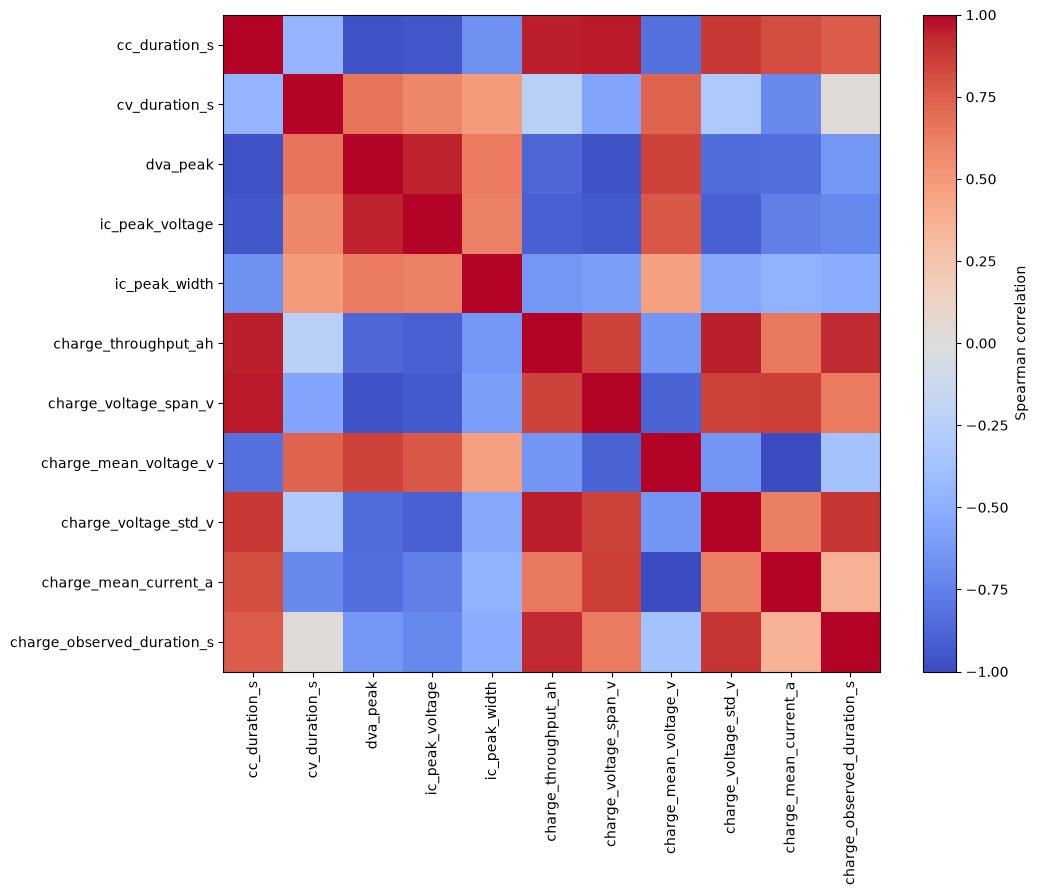

In [21]:
if len(READY)>=30:
    redundancy=READY[CANDIDATES].corr(method='spearman',min_periods=15)
    redundancy.to_csv(OUT_DIR/'feature_redundancy_spearman.csv')
    per_cell=[]
    for cell,g in READY.groupby('cell_id'):
        for feat in CANDIDATES:
            r,rho,tau,n=safe_correlations(g[feat],g.soh)
            per_cell.append({'cell_id':cell,'feature':feat,'n':n,'pearson_r':r,'spearman_rho':rho,'kendall_tau':tau})
    stability=pd.DataFrame(per_cell)
    stability.to_csv(OUT_DIR/'per_cell_feature_correlations.csv',index=False)
    display(stability.pivot(index='feature',columns='cell_id',values='spearman_rho').round(2))
    plt.figure(figsize=(11,9));plt.imshow(redundancy,vmin=-1,vmax=1,cmap='coolwarm');plt.colorbar(label='Spearman correlation')
    plt.xticks(range(len(CANDIDATES)),CANDIDATES,rotation=90);plt.yticks(range(len(CANDIDATES)),CANDIDATES)
    plt.tight_layout();plt.savefig(OUT_DIR/'feature_redundancy.png',dpi=180);plt.show()

## 7. Leakage-resistant cross-battery predictive feature ranking

Perform **grouped battery-held-out validation** of Ridge regression with training-only median imputation and standardization. Score candidate sets using weighted mean held-out RMSE, MAE and R². All validation targets belong to batteries unseen during fitting. Forward selection chooses up to five features using GroupKFold, using *only the available batteries*. These scores estimate **same-cycle estimation** (charge features paired with discharge SOH), not 1/3/5-step forecasting. For forecasting, shift target by horizon within each cell and repeat the grouped protocol.

In [22]:
def evaluate_battery_cv(frame,features,target='soh',n_splits=5):
    d=frame.dropna(subset=[target,'cell_id']).copy()
    cells=d.cell_id.unique()
    if len(cells)<3:return None
    splits=min(n_splits,len(cells)); model=make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),Ridge(alpha=10.0))
    pred=np.full(len(d),np.nan); per=[]
    cv=GroupKFold(n_splits=splits)
    for fold,(train,test) in enumerate(cv.split(d[features],d[target],d.cell_id)):
        model.fit(d.iloc[train][features],d.iloc[train][target])
        yp=model.predict(d.iloc[test][features]);pred[test]=yp;yt=d.iloc[test][target].to_numpy()
        per.append({'fold':fold,'heldout_cells':','.join(sorted(d.iloc[test].cell_id.unique())),
                    'n_test':len(test),'rmse':np.sqrt(mean_squared_error(yt,yp)),
                    'mae':mean_absolute_error(yt,yp),'r2':r2_score(yt,yp) if len(yt)>1 else np.nan})
    f=pd.DataFrame(per)
    return {'rmse':float(np.sqrt(mean_squared_error(d[target],pred))),'mae':float(mean_absolute_error(d[target],pred)),
            'r2':float(r2_score(d[target],pred)),'per_fold':f}

if len(READY)>=30 and READY.cell_id.nunique()>=3:
    comparisons=[]
    for feature in CANDIDATES:
        z=evaluate_battery_cv(READY,[feature]);comparisons.append({'feature':feature,'heldout_rmse':z['rmse'],'heldout_mae':z['mae'],'heldout_r2':z['r2']})
    single=pd.DataFrame(comparisons).sort_values('heldout_rmse');single.to_csv(OUT_DIR/'single_feature_groupcv.csv',index=False)
    display(single.round(5))
    available=list(CANDIDATES);selected=[];progress=[]
    for round_idx in range(min(5,len(available))):
        tested=[]
        for f in available:
            z=evaluate_battery_cv(READY,selected+[f])
            tested.append((z['rmse'],f,z))
        score,f,z=min(tested,key=lambda a:a[0]);selected.append(f);available.remove(f)
        progress.append({'step':round_idx+1,'feature_added':f,'feature_subset':' | '.join(selected),
                         'heldout_rmse':z['rmse'],'heldout_mae':z['mae'],'heldout_r2':z['r2']})
    progression=pd.DataFrame(progress)
    progression.to_csv(OUT_DIR/'forward_selection_groupcv.csv',index=False)
    display(progression)
    five_eval=evaluate_battery_cv(READY,FIVE_F2)
    five_eval['per_fold'].to_csv(OUT_DIR/'original_five_feature_groupcv_folds.csv',index=False)
    display(pd.DataFrame([dict(subset='original_five_F2', **{k:v for k,v in five_eval.items() if k!='per_fold'})]))
    print('Selected five from this run:',selected)
else:
    print('BLOCKED: at least 3 independent batteries and >=30 accepted cycles required for grouped feature ranking.')

,feature,heldout_rmse,heldout_mae,heldout_r2
5,charge_throughput_ah,0.09919,0.07667,0.60922
3,ic_peak_voltage,0.15882,0.14203,-0.00183
0,cc_duration_s,0.16482,0.14402,-0.07904
6,charge_voltage_span_v,0.19491,0.17143,-0.50894
2,dva_peak,0.19732,0.16830,-0.54654
4,ic_peak_width,0.19772,0.16879,-0.55267
7,charge_mean_voltage_v,0.20125,0.16913,-0.60872
10,charge_observed_duration_s,0.20221,0.19306,-0.62411
8,charge_voltage_std_v,0.20469,0.17295,-0.66418
1,cv_duration_s,0.21065,0.16450,-0.76249


,step,feature_added,feature_subset,heldout_rmse,heldout_mae,heldout_r2
0,1,charge_throughput_ah,charge_throughput_ah,0.099190,0.076669,0.609221
1,2,charge_voltage_span_v,charge_throughput_ah | charge_voltage_span_v,0.068396,0.050366,0.814192
2,3,dva_peak,charge_throughput_ah | charge_voltage_span_v |...,0.069740,0.051285,0.806822
3,4,ic_peak_voltage,charge_throughput_ah | charge_voltage_span_v |...,0.077684,0.049939,0.760307
4,5,cc_duration_s,charge_throughput_ah | charge_voltage_span_v |...,0.089265,0.072502,0.683510


,subset,rmse,mae,r2
0,original_five_F2,0.243693,0.224425,-1.358753


Selected five from this run: ['charge_throughput_ah', 'charge_voltage_span_v', 'dva_peak', 'ic_peak_voltage', 'cc_duration_s']


## 8. Paper-ready extraction/QC summary and diagnostic plots

,metric,value
0,raw_files,526.000000
1,sheets_inspected,1245.000000
2,candidate_raw_sheets,457.000000
3,cycle_pairs_extracted,2269.000000
4,cycle_pairs_qc_pass,2168.000000
5,independent_cells_qc_pass,10.000000
6,mean_missing_five_features_pct,4.072279
7,median_soh,0.748736


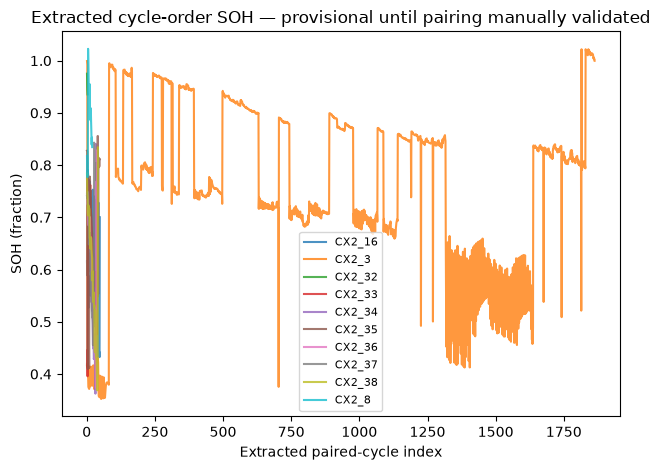

Saved files under C:\Projects\Battery_Soh\calce_raw_feature_research


In [23]:
if len(cycle_df):
    tab=pd.DataFrame([{'metric':'raw_files','value':len(files)},
      {'metric':'sheets_inspected','value':len(schema)},
      {'metric':'candidate_raw_sheets','value':int((schema.status=='candidate').sum())},
      {'metric':'cycle_pairs_extracted','value':len(cycle_df)},
      {'metric':'cycle_pairs_qc_pass','value':len(READY)},
      {'metric':'independent_cells_qc_pass','value':READY.cell_id.nunique()},
      {'metric':'mean_missing_five_features_pct','value':float(100*cycle_df[FIVE_F2].isna().mean().mean())},
      {'metric':'median_soh','value':float(cycle_df.soh.median())}])
    tab.to_csv(OUT_DIR/'paper_extraction_summary.csv',index=False)
    display(tab)
    for cell,g in READY.groupby('cell_id'):
        plt.plot(np.arange(len(g))+1,g.soh,label=cell,alpha=.8)
    plt.title('Extracted cycle-order SOH — provisional until pairing manually validated');plt.xlabel('Extracted paired-cycle index');plt.ylabel('SOH (fraction)')
    if READY.cell_id.nunique()<=12:plt.legend(fontsize=8)
    plt.tight_layout();plt.savefig(OUT_DIR/'soh_by_cell.png',dpi=180);plt.show()
print('Saved files under',OUT_DIR.resolve())

## 9. Manual validation and publication checklist

**MANDATORY BEFORE PAPER CLAIMS:**

- [ ] Check battery ID parsing: `CS2_33` must remain `CS2_33` and not collapse to `CS2_2`.
- [ ] Confirm per-cell chemistry, nominal capacity, charge current polarity and protocol from authoritative CALCE metadata.
- [ ] Inspect at least 5 random cycles per battery against raw current/voltage/time traces; verify that each charge is paired with its correct discharge.
- [ ] Review long-gap and incomplete-discharge rejections; never relabel unknown gaps as measured rest.
- [ ] Verify that multi-file battery sessions do not contain repeated cycle resets or overlapping timestamps. If they do, implement file/session-aware chronology before publication.
- [ ] Check that all feature extraction is available at prediction time and discharge capacity is used only as the reference label.
- [ ] Reconcile IC/DVA processing choices (smoothing, voltage range, prominence and curve reconstruction) against your original F2 feature extractor before claiming exact reproduction.
- [ ] Report per-cell counts, rejection counts, missing feature fractions, Pearson/Spearman/MI results and held-out uncertainty.
- [ ] Keep same-cycle feature ranking separate from future-cycle SOH forecasts, and avoid selecting features on the held-out test battery.

**Interpretation:** Correlation is descriptive; a predictive ranking is only meaningful after the raw cycle reconstruction passes the QC gate. No statistics in this notebook are fabricated.